# Neighbourhood-dependent differential expression with spidepy

This walk-through follows the "Getting started" article of [spiDE](https://github.com/BhuvaLab/spiDE) (R commit
`c8db60a`) section by section on its shipped example (`toy_spide()`), using spidepy.

`spidepy` finds **neighbourhood-dependent differential expression** in spatial transcriptomics.
Within an *index* cell type, it asks whether a gene's expression changes with the local density
(the *niche*) of another cell type. One hypothesis is one (gene, index type, niche type)
*triplet*, and two questions are asked of it:

- **the pooled test**: within patients, does the gene's expression in the index type change with
  the density of the niche type, consistently across patients?
- **the condition test**: does that dependence differ between two conditions (for example
  responders and non-responders)?

Both are questions about patients. The condition is a property of a patient, not of a cell, so the
patient is the unit of replication: a triplet's evidence is the variation of its niche slope
*between* patients, never the number of cells.

Both tests look at slopes *within* patients. A condition that only shifts a gene's overall level,
or only changes how much of a cell type patients have, is not tested here (those are questions for
pseudobulk differential expression and composition analysis). Between-patient association with a
niche is tested separately by `test_niche_abundance()`.

There are three steps:

1. **Niches**: `build_niches()` computes, per sample, a Gaussian kernel density of every cell type at every cell.
2. **Fit**: `fit_spide()` fits, for each index cell type, one negative binomial GLM per gene on the niche
   densities with an intercept per patient, so each niche coefficient is a within-patient slope.
3. **Test**: `test_spide()` tests those slopes across patients. It always runs the pooled test, and runs the
   condition test when it has a condition.

`spide()` runs all three.

In [1]:
%matplotlib inline
import matplotlib
from IPython.display import display

import spidepy as sp

matplotlib.rcParams["figure.dpi"] = 90

## Load the data

spidepy needs an `AnnData` with

- **raw integer counts** (in `layers["counts"]` here; `assay=` names another layer, and `"X"` uses `adata.X`);
- a **cell type** per cell (`obs["cell_type"]`);
- a **patient** per cell (`obs["sample_id"]`). One sample per patient: if a patient has several sections,
  give the patient in `sample_id` and the section in `section=`, so the spatial variance is estimated per section;
- spatial coordinates in `obsm["spatial"]`;
- for the condition test, a **two-level condition that is constant within a patient**.

The example has 16 patients (eight responders, eight non-responders), three cell types and 20 genes. It plants
one effect: gene `G1` is up-regulated in index type `A`, in responders only, in proportion to the local density
of niche type `B`.

In [2]:
adata = sp.datasets.toy_spide()
print(adata)
patients = adata.obs[["sample_id", "condition"]].drop_duplicates()
print(patients["condition"].value_counts())
print(adata.obs["cell_type"].value_counts())

AnnData object with n_obs × n_vars = 2400 × 20
    obs: 'sample_id', 'condition', 'x', 'y', 'cell_type', 'Age', 'cell_id', 'Area', 'nCount'
    uns: 'r_call', 'r_dim'
    obsm: 'spatial'
    layers: 'counts', None (.X)
condition
Responder        8
Non-responder    8
Name: count, dtype: int64
cell_type
C    861
A    813
B    726
Name: count, dtype: int64


## Build the niches

`build_niches()` places a smooth bump, a Gaussian kernel, on every cell of a given type and adds the bumps up, giving a density of each cell type at every cell: how much of that type there is nearby. The width of the bump, `sigma`, is the *bandwidth*, in the units of the spatial coordinates. Each density matrix is stored in `obsm` under `Niche<sigma>`. It works in place unless `copy=True`.

In [3]:
sp.build_niches(adata, sigma=30)
adata.obsm["Niche30"].head(3)

,A,B,C
cell1,0.656945,1.471217,0.294722
cell2,1.412475,0.000353,1.244943
cell3,0.735279,0.000000,1.418453


### Choose a bandwidth

The bandwidth sets what we mean by a neighbourhood. A small bandwidth looks at the immediate neighbours of a cell, and a large one at the tissue around it. A good bandwidth gives a niche map that is neither speckled nor flat. We can look at the density of niche type `B` in one sample at two bandwidths and judge by eye (`copy=True` leaves `adata` with the bandwidth 30 only):

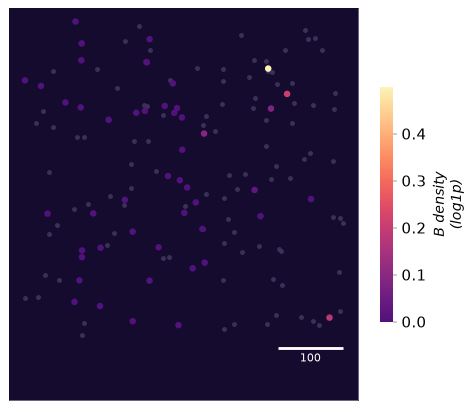

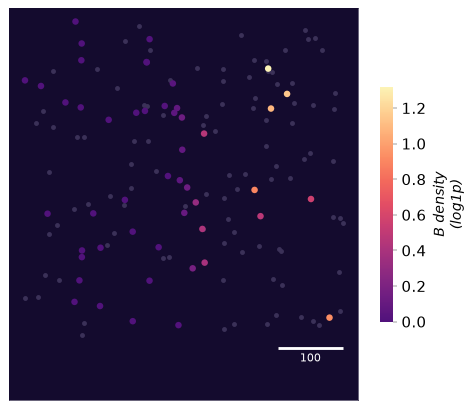

In [4]:
adata10 = sp.build_niches(adata, sigma=10, copy=True)
display(sp.pl.plot_niche_map(adata10, niche="B", sample="S1", index="A", sigma=10))
display(sp.pl.plot_niche_map(adata10, niche="B", sample="S1", index="A", sigma=30))

At the smaller bandwidth most cells have no niche cell of type `B` within reach and the density is zero, so the map is speckled by the position of single cells. At the larger one the density varies smoothly across the section, and we can see where `B` cells are concentrated. We use 30 for the rest of this article. For real data, choose the bandwidth from what you know about the biology, such as the distance over which cells signal to one another, and from maps like these. `merge_niches()` can pool several cell types into one niche group (all lymphocytes, say) before fitting. spidepy never tests an index type against its own niche, merged or not.

## Fit the model

`fit_spide()` takes the object with its niches, the bandwidth to use and, if we want to test a condition, the name
of the condition column. By default it fits every index type with at least `min_cells` cells in at least
`min_patients` patients (`index` restricts it), and tests every other cell type as a niche (`niche` restricts it;
the others stay in the model as adjustments). Genes detected in fewer than `min_detect` of an index type's cells
are not tested in it. Sequencing depth enters as the centred log library size of each cell (`depth="loglib"`);
cell-level covariates are added with `covariates`.

In [5]:
fit = sp.fit_spide(adata, condition="condition", sigma=30, verbose=False)
fit

SpiDEFit (slopes engine), bandwidth 30
  16 patients; condition: condition
  index A: 20 genes x 2 niches (B, C)
  index B: 20 genes x 2 niches (A, C)
  index C: 20 genes x 2 niches (A, B)

`engine` chooses how the between-patient error is estimated:

- **`"slopes"`** (the default) fits the model once, without the condition, then estimates every patient's own
  niche slopes, each with a variance that allows for spatially correlated cells. `test_spide()` combines them
  across patients, allowing the slope to vary between patients. Because the fit never sees the condition, any
  patient-level condition can be tested afterwards, and a permutation of the condition reruns only the test.
- **`"sandwich"`** fits the condition-specific model directly and tests its coefficients with a
  patient-clustered sandwich standard error. It needs the condition at fit time.

The slopes engine is the more powerful, most of all when effects vary between patients, and it is needed for
`spi_gsea()`.

## Test the slopes

`test_spide()` combines the patients' slopes. It always runs the pooled test, and it runs the condition-specific test when a condition is available, here the one recorded by `fit_spide()`. A condition can also be given to `test_spide()` directly. It returns a `SpiDEResults`; `results()` gives its tables.

In [6]:
res = sp.test_spide(fit)
print(res)

SpiDEResults (slopes engine)
  pooled across patients: 120 tests, 2 at FDR 0.05
  condition-specific (Responder - Non-responder; pooled_or_heterogeneity family): 2 tests, 1 at FDR 0.05


### The pooled test

The pooled results are a table with one row per triplet. `estimate` is the average within-patient slope on the natural-log scale per unit of the log1p niche density, `t` and `p` are the test statistic and its p-value, and `q` is the q-value after a Benjamini-Hochberg correction over every triplet.

In [7]:
sp.results(res, test="pooled").head()

,gene,index,niche,test,estimate,se,t,df,p,n_patients,p.heterogeneity,q,in_family
0,G1,A,B,pooled,0.388137,0.056796,6.833884,238.200655,6.861903e-11,16.0,0.554557,8.234284e-09,True
1,G9,A,B,pooled,-0.410807,0.096407,-4.261157,275.751771,2.794132e-05,16.0,0.254027,1.676479e-03,True
2,G8,B,C,pooled,-1.011057,0.313747,-3.222522,278.860951,1.421456e-03,16.0,0.103677,5.685822e-02,True
3,G18,A,B,pooled,-0.459829,0.172452,-2.666419,260.583332,8.145921e-03,16.0,0.884934,2.443776e-01,True
4,G2,A,B,pooled,-0.374695,0.156733,-2.390654,273.314699,1.749550e-02,16.0,0.259633,4.198921e-01,True


The planted triplet, `G1` in `A` against `B`, comes out as the strongest pooled association. Remember that a pooled call says that, within a patient, index cells with more of the niche type around them express more (or less) of the gene, consistently across patients.

### The condition-specific test

The condition-specific table has the same layout. Its `estimate` is the difference between the conditions in the average slope, the second level minus the first, and `res.contrast` says which two levels were compared.

In [8]:
print(res.contrast)
cond = sp.results(res, test="condition")
cond[cond["in_family"]]

Responder - Non-responder


,gene,index,niche,test,estimate,se,t,df,p,n_patients,p.heterogeneity,q,in_family
1,G1,A,B,condition,0.273114,0.088514,3.085553,11.312847,0.010056,16.0,0.554557,0.020112,True
33,G9,A,B,condition,-0.240882,0.210066,-1.146697,12.844779,0.272419,16.0,0.254027,0.272419,True


By default (`procedure="pooled_or_heterogeneity"`) the condition test is carried out only among the triplets
that pass the pooled test or whose slopes vary between patients more than their sampling noise allows
(`p.heterogeneity`, Benjamini-Hochberg at `fdr`). Neither filter looks at the condition, so the family is exact
under any relabelling of patients, and the multiplicity correction is spent on triplets with something for the
condition to explain. Rows outside the family have `q = NaN`. `procedure="heterogeneity"` and
`procedure="filtered"` use one filter each, and `procedure="all"` tests every triplet.

In [9]:
pooled = sp.results(res, test="pooled")
g1 = cond[(cond["gene"] == "G1") & (cond["index"] == "A") & (cond["niche"] == "B")].iloc[0]
print(f"planted triplet: pooled t = {pooled['t'].iloc[0]:.2f} (strongest); "
      f"responders - non-responders = {g1['estimate']:.2f} log units per unit log1p density, q = {g1['q']:.2g}")

planted triplet: pooled t = 6.83 (strongest); responders - non-responders = 0.27 log units per unit log1p density, q = 0.02


The whole pipeline can also be run in one call. `spide()` builds the niche matrix itself and does not keep it on the object (`name=` is the `obsm` prefix the niches are read from, or built into):

In [10]:
res2 = sp.spide(sp.datasets.toy_spide(), condition="condition", sigma=30, verbose=False)
print(res2)

SpiDEResults (slopes engine)
  pooled across patients: 120 tests, 2 at FDR 0.05
  condition-specific (Responder - Non-responder; pooled_or_heterogeneity family): 2 tests, 1 at FDR 0.05


## Look at the patients behind a result

A call is only as good as the patients behind it. With the slopes engine, every patient has its own slope for every triplet, and these slopes are the evidence that the tests weigh. `patient_slopes()` returns them as a table, with the slope's variance and the number of cells that went into it.

In [11]:
ps = sp.patient_slopes(fit, gene="G1", index="A", niche="B")
ps[["patient", "condition", "slope", "var_spatial", "ncells"]].head()

,patient,condition,slope,var_spatial,ncells
0,S1,Responder,0.465072,0.008294,49
1,S10,Non-responder,0.176669,0.059603,61
2,S11,Responder,0.400428,0.010850,60
3,S12,Non-responder,0.204428,0.084545,41
4,S13,Responder,0.401380,0.021371,54


`pl.plot_patient_slopes()` draws them. Each point is a patient's slope with its interval, sized by the weight the patient carries in the tests. The weighted average of each condition is marked, and the pooled estimate is shown as a band.

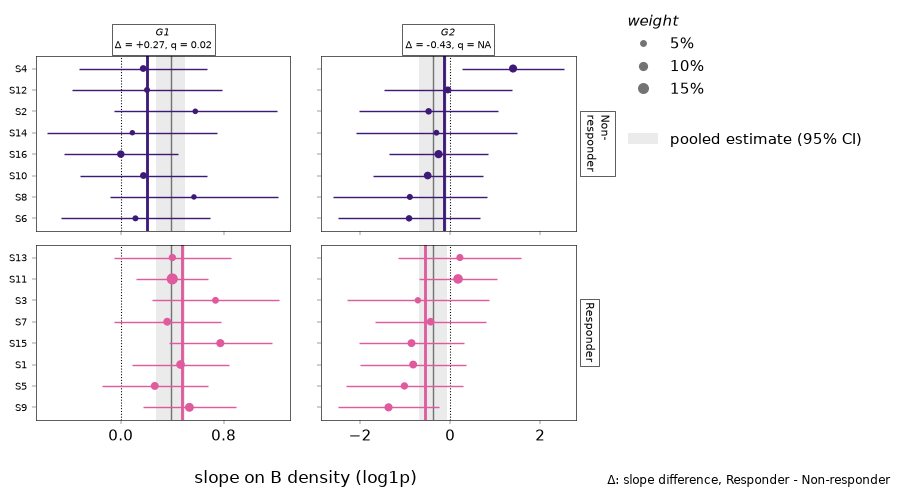

In [12]:
display(sp.pl.plot_patient_slopes(res, gene=["G1", "G2"], index="A", niche="B"))

For `G1`, the slopes of the patients lie mostly above zero in both conditions, which gives the pooled call, and the slopes of the responders sit further to the right than those of the non-responders, which is what the condition-specific test picks up. For `G2`, which has no planted effect, the slopes are spread widely on both sides of zero, their intervals are wide, and the two conditions overlap.

The model also gives each patient a baseline level of every gene, its intercept. These baselines absorb everything that differs between patients as a whole, so they are not tested, but they are worth a look. `patient_intercepts()` returns them with the patient-level covariates, and `pl.plot_patient_effects()` summarises them by principal components of the intercepts, showing how much of each component each covariate explains.

In [13]:
intercepts = sp.patient_intercepts(fit, gene="G1", index="A")
intercepts.head()

,gene,index,patient,intercept,ncells,sample_id,condition,Age
0,G1,A,S1,2.185319,49,S1,Responder,0.525262
1,G1,A,S10,1.782854,61,S10,Non-responder,-2.566746
2,G1,A,S11,2.157735,60,S11,Responder,1.213412
3,G1,A,S12,1.627117,41,S12,Non-responder,0.362418
4,G1,A,S13,2.223423,54,S13,Responder,-1.853804


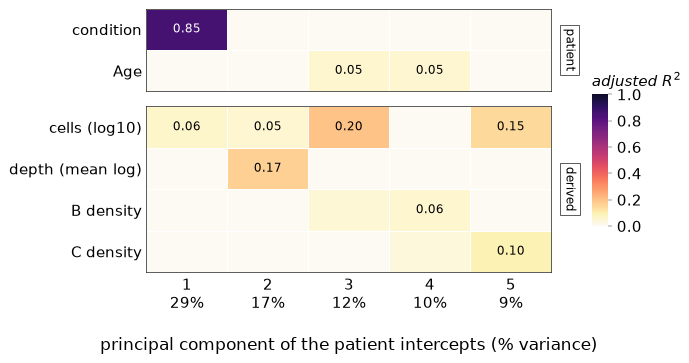

In [14]:
display(sp.pl.plot_patient_effects(res, index="A"))

In this example the first component of the intercepts lines up almost entirely with the condition, which is what we expect: the baselines absorb the difference in level between responders and non-responders, so that this difference cannot be mistaken for a difference in slope. If a slide or batch column lined up with a component of the *slopes* instead, the condition would be partly confounded with it, and that column should go into `strata`. Setting `niche` in `plot_patient_effects()` draws the same plot for the slopes, which is the check to make before trusting a condition-specific call.

## Test gene sets

`spi_gsea()` tests gene sets the way `test_spide()` tests genes. Each patient gets a slope for the set: the average
of its genes' slopes, each gene put on a common scale. By default the average over all other tested genes is
subtracted, so a set is called when it moves *more than the typical gene* (`type="competitive"`). The set slopes
then go through the pooled and the condition test, so the correlation between genes of a set is accounted for
without being estimated. Any dict of gene symbol lists works, for example MSigDB collections.

In [15]:
sets = {
    "planted": ["G1", "G2", "G3"],
    "other": [f"G{i}" for i in range(4, 9)],
    "rest": [f"G{i}" for i in range(9, 21)],
}
gs = sp.spi_gsea(res, sets, min_size=3)
gs[["set", "index", "niche", "test", "size", "estimate", "p", "q", "q.global"]].head()

,set,index,niche,test,size,estimate,p,q,q.global
0,planted,A,B,pooled,3,0.578673,0.000011,0.000032,0.000191
1,planted,C,A,pooled,3,0.237550,0.045308,0.135925,0.233513
2,other,B,C,pooled,5,-0.215171,0.048372,0.145115,0.233513
3,planted,B,A,pooled,3,0.270073,0.051892,0.155676,0.233513
4,rest,A,B,pooled,12,-0.195542,0.094970,0.142454,0.341890


`q` adjusts within each (index, niche, test) column and `q.global` over every set, index and niche of a test.
With many sets and many columns, `q.global` is the one to read. `pl.plot_triplet_heatmap()` shows the sets' t
across every (index, niche) column, with a dot where `q.global` passes.

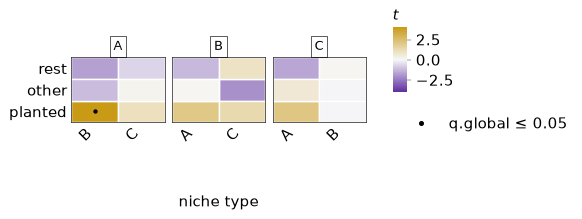

In [16]:
display(sp.pl.plot_triplet_heatmap(gs, test='pooled'))

The set holding the planted gene stands out in the column of `A` against `B`, where it is called, and no other set is called.

## A different question: niche abundance

The slopes are within-patient. A patient whose index cells sit among many niche cells may also express a gene
differently, as a whole, from a patient whose index cells do not; that between-patient association is absorbed by
the patient intercepts and is invisible to `test_spide()`. It is a different claim: that patients with more of a
niche type differ, not that a cell responds to its neighbours. `test_niche_abundance()` asks it on pseudobulk
profiles, one per patient and index type, against the patient's mean niche density.

In [17]:
ab = sp.test_niche_abundance(adata, condition="condition", sigma=30, verbose=False)
ab.head()

,gene,index,niche,term,estimate,t,p,n_patients,leverage,downweighted,q,q.global
0,G1,A,B,niche,-0.702703,-0.767075,0.453956,16,3.140745,1,0.770461,0.945496
1,G2,A,B,niche,1.696534,0.994912,0.334588,16,3.140745,1,0.770461,0.907598
2,G3,A,B,niche,-4.467735,-2.203907,0.042523,16,3.140745,1,0.770461,0.662375
3,G4,A,B,niche,1.675993,1.089477,0.292081,16,3.140745,1,0.770461,0.907598
4,G5,A,B,niche,-2.309309,-1.504881,0.151839,16,3.140745,1,0.770461,0.737781


With a condition, the rows with `term` `"niche"` give the association averaged over the two conditions, and those
with `"condition:niche"` test whether it differs between them (second level minus first). Each term is its own
multiple-testing family (`q.global`), and a patient who alone carries most of a niche type's spread is
down-weighted (`max_leverage`), so that one patient cannot make a call on its own. Gene sets go through the same
test with `test_niche_abundance(genesets=...)`.

Never report a result of one test as a result of the other.

`pl.plot_niche_response()` shows both on one gene. With `adjust=False` it draws the raw data: each segment is one patient's slope, the quantity spidepy tests, and the dashed line through the patients' means is the between-patient association that `test_niche_abundance()` tests.

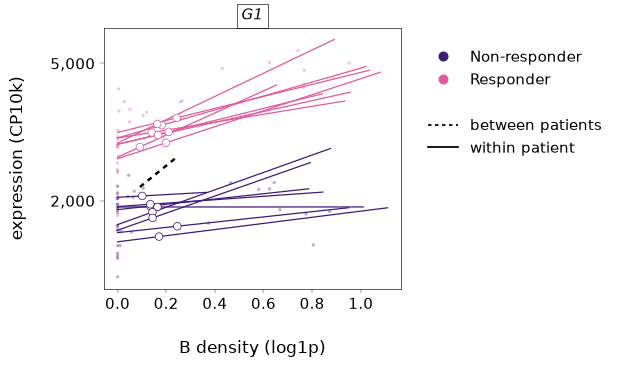

In [18]:
display(sp.pl.plot_niche_response(adata, res, gene="G1", index="A", niche="B", adjust=False))

## Plots

Every plot is a matplotlib `Figure` in one house style and one colour-blind-safe palette (`pl.style()`, `pl.spide_colours()`): gold and violet for a slope that rises or falls with the niche's density, and dark violet and pink for the first and second level of the condition. Magnitudes use a light-to-dark magma ramp, and the niche map, drawn in tissue coordinates on a dark panel, its brighter `"spatial"` part.

### Where the calls are

`pl.plot_call_map()` counts, for each (index, niche) column, how many triplets pass, separately for slopes that rise and slopes that fall with the niche's density, and `pl.plot_top_triplets()` shows the strongest ones. With `adata`, a triangle marks a gene that is several-fold higher in the niche type than in the index type, which we come back to below.

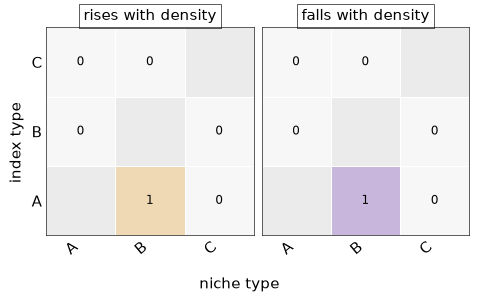

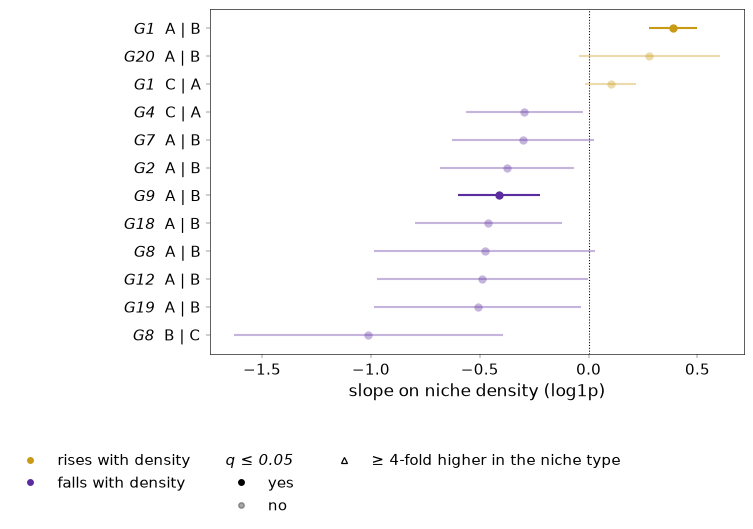

In [19]:
display(sp.pl.plot_call_map(res, test="pooled"))
display(sp.pl.plot_top_triplets(res, test="pooled", n=12, adata=adata))

### The cells behind a slope

`pl.plot_niche_response()` shows the cells themselves. By default, each patient's fitted intercept is divided out, so the patients share one level and the slopes that the tests compare are easy to see.

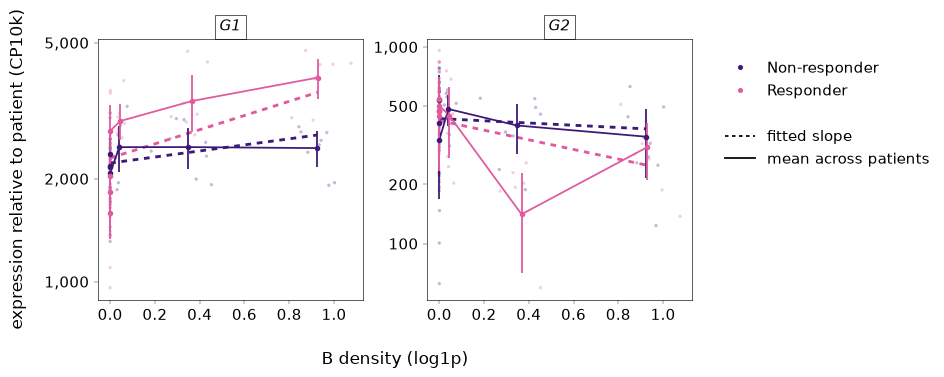

In [20]:
display(sp.pl.plot_niche_response(adata, res, gene=["G1", "G2"], index="A", niche="B"))

For `G1`, the expression of the responders' cells rises with the density of `B` while that of the non-responders is nearly flat. For `G2`, there is no clear trend in either group.

### Check for spillover

Cell segmentation is never perfect, and transcripts of a neighbouring niche cell can be assigned to an index cell. These transcripts rise with the niche's density and look like a response of the index cell. `pl.plot_spillover()` plots every triplet by its signed z statistic against how much higher the gene is in the niche type than in the index type, and marks the region of genes that are several-fold higher in the niche type. If the calls fell mostly in that region, they would be the niche type's own markers and spillover the likely explanation.

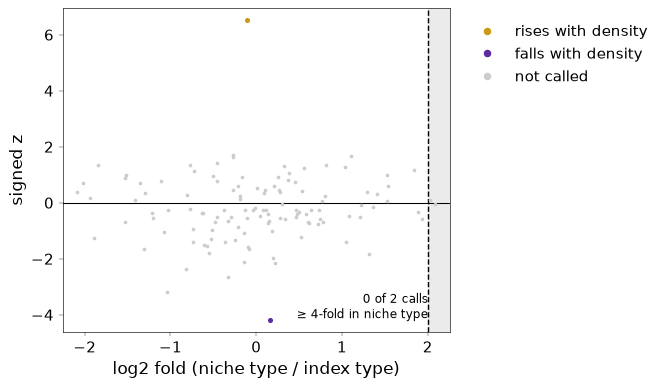

In [21]:
display(sp.pl.plot_spillover(res, adata))

### Diagnostics

`pl.plot_p_values()` shows the distribution of the p-values by expression band. It is a sanity check on the data at hand and is not a replacement for calibration checks.

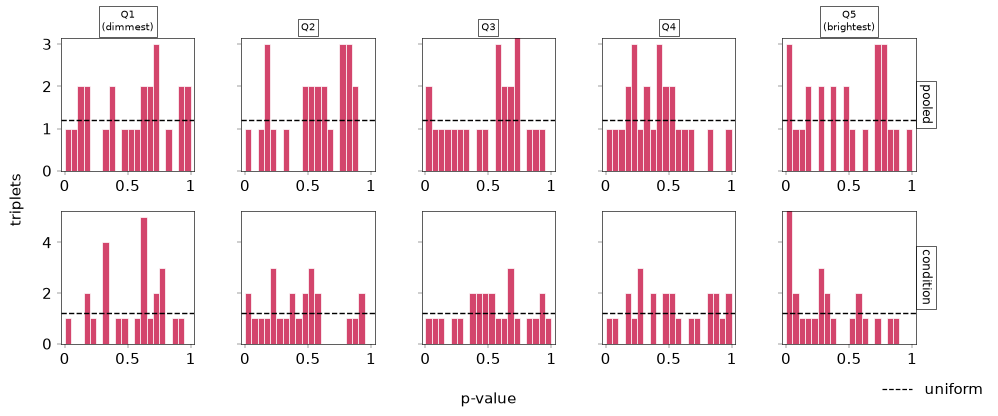

In [22]:
display(sp.pl.plot_p_values(res))

## Practicalities

- **Parallelism.** Genes are fitted independently given an index type, so `n_jobs` parallelises over genes
  (it replaces R's `BPPARAM`). Results are identical for any `n_jobs`.
- **Counts must be integers.** A back-transformed normalised layer is not a count and is refused.
- **Sparse input.** `layers["counts"]` can be a CSR or CSC matrix and gives the same results as dense.
- **Differences from R.** See `docs/r-discrepancies.md`.
- **Several bandwidths.** One fit uses one bandwidth. We can build the niches at several bandwidths and fit each one, but the results are a sensitivity analysis and not a search: each bandwidth is its own set of tests, and picking the best of them after looking would not be valid. Calls that hold at both bandwidths are the more convincing.

Below we refit index type `A` at the smaller bandwidth and count the pooled calls at each bandwidth.

In [23]:
fit10 = sp.fit_spide(adata10, condition="condition", sigma=10, index="A", verbose=False)
r10 = sp.results(sp.test_spide(fit10), test="pooled")
r30 = sp.results(res, test="pooled")
r30 = r30[r30["index"] == "A"]
print({"sigma10": int((r10["q"] < 0.05).sum()), "sigma30": int((r30["q"] < 0.05).sum())})

{'sigma10': 3, 'sigma30': 2}


## Session information

In [24]:
import platform
from importlib.metadata import version

pkgs = ["spidepy", "spanormpy", "anndata", "numpy", "pandas", "scipy"]
print(platform.python_version(), {p: version(p) for p in pkgs})

3.12.15 {'spidepy': '0.1.0.dev0', 'spanormpy': '0.1.0', 'anndata': '0.13.4', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.18.1'}
